# Day 4 · Demo 1: two unknowns

Bayesian statistics for PhD researchers, Aalborg University 2026. This notebook reproduces the figures of the **Day 4 morning slides**. Each section names its slide. Run it with the **R (bayes)** kernel from the `demos/` folder; the first Stan fit compiles the model (about a minute).

The data are the slides' **illustrative** time-game data: people trying to wait 10 seconds, without feedback. Here we use one person, P04.

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # dplyr for summaries, ggplot2 for figures
library(cmdstanr)    # Stan from R
set.seed(2026)
options(width = 95, repr.plot.width = 8, repr.plot.height = 5, repr.plot.bg = "white")

d <- read_csv("data/slides-class-timing.csv", show_col_types = FALSE)   # person, attempt, seconds
d |> count(person)

This is cmdstanr version 0.9.0

- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr

- CmdStan path: /opt/homebrew/Caskroom/miniconda/base/envs/bayes/bin/cmdstan

- CmdStan version: 2.40.0



person,n
<chr>,<int>
P01,10
P02,10
P03,10
P04,10
P05,10
P06,10
P07,8
P08,6
P09,5


## 1. One person, ten attempts

*Slide "One person, ten attempts".*

[1]  9.2  9.8  9.4 10.0  9.8 10.7 10.2  8.9 10.2  8.9

mean        sd 
9.7100000 0.5989806

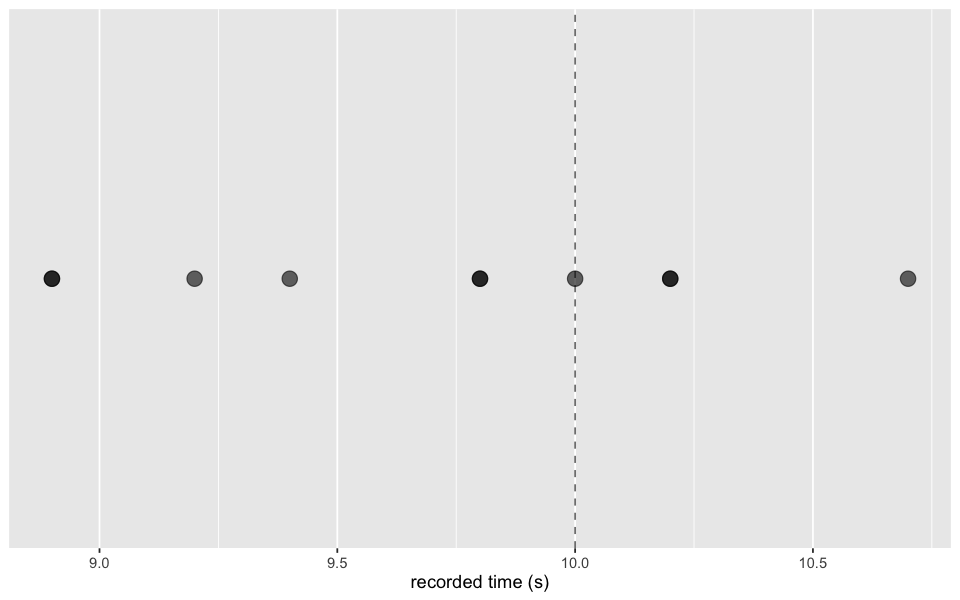

In [2]:
y <- d |> filter(person == "P04") |> pull(seconds)
y
c(mean = mean(y), sd = sd(y))

ggplot(tibble(seconds = y), aes(x = seconds, y = 0)) +
  geom_vline(xintercept = 10, linetype = "dashed", colour = "grey50") +
  geom_point(size = 4, alpha = 0.6) +
  scale_y_continuous(breaks = NULL) + labs(y = NULL, x = "recorded time (s)")

## 2. The posterior on a grid

*Slide "Bayes' rule with two parameters".* The model: yᵢ ~ Normal(μ, σ), priors μ ~ Normal(10, 2) and σ ~ Normal⁺(0, 2). As on Day 2, we compute likelihood × prior at many points, now on a grid of (μ, σ) pairs, and rescale so that the weights add up to 1.

The log-likelihood is a sum over the ten attempts, so we add one attempt at a time.

[1] 31161

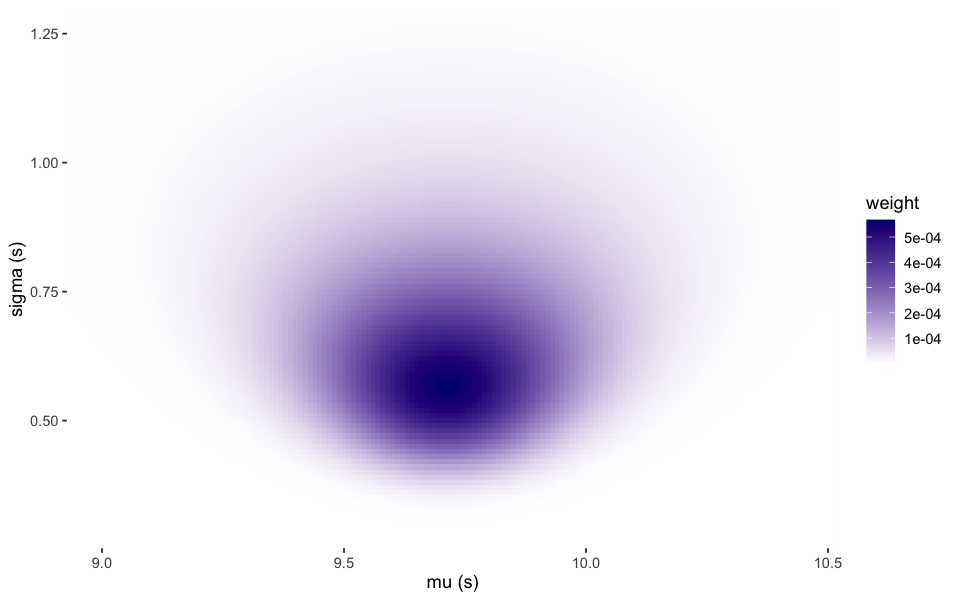

In [4]:
grid <- expand_grid(mu = seq(8.6, 10.8, length.out = 221), sigma = seq(0.2, 1.6, length.out = 141))

log_lik <- 0
for (yi in y) log_lik <- log_lik + dnorm(yi, grid$mu, grid$sigma, log = TRUE)

grid <- grid |>
  mutate(log_post = log_lik + dnorm(mu, 10, 2, log = TRUE) + dnorm(sigma, 0, 2, log = TRUE),
         weight   = exp(log_post - max(log_post)),     # subtract the max to avoid tiny numbers
         weight   = weight / sum(weight))              # weights add up to 1
nrow(grid)

ggplot(grid, aes(x = mu, y = sigma, fill = weight)) +
  geom_raster() + scale_fill_gradient(low = "white", high = "navy") +
  coord_cartesian(xlim = c(9, 10.45), ylim = c(0.3, 1.25)) +
  labs(x = "mu (s)", y = "sigma (s)")

In [6]:
head(grid)

mu,sigma,log_post,weight
<dbl>,<dbl>,<dbl>,<dbl>
8.6,0.20,-190.9442,9.086385e-82
8.6,0.21,-173.3614,3.930739e-74
8.6,0.22,-158.1638,1.565731e-67
8.6,0.23,-144.9438,8.631497e-62
8.6,0.24,-133.3772,9.107473e-57
8.6,0.25,-123.2034,2.386854e-52


## 3. Marginal and conditional on the grid

*Slides "Marginalising on a grid" and "Conditional is not marginal".*

- **Marginal** of μ: add the weights over σ, i.e. sum the weights for each value of μ.
- **Conditional** of μ given σ: keep one value of σ (one column of the grid) and rescale it to sum to 1.

mean_mu mean_sigma 
 9.7136099  0.6910882

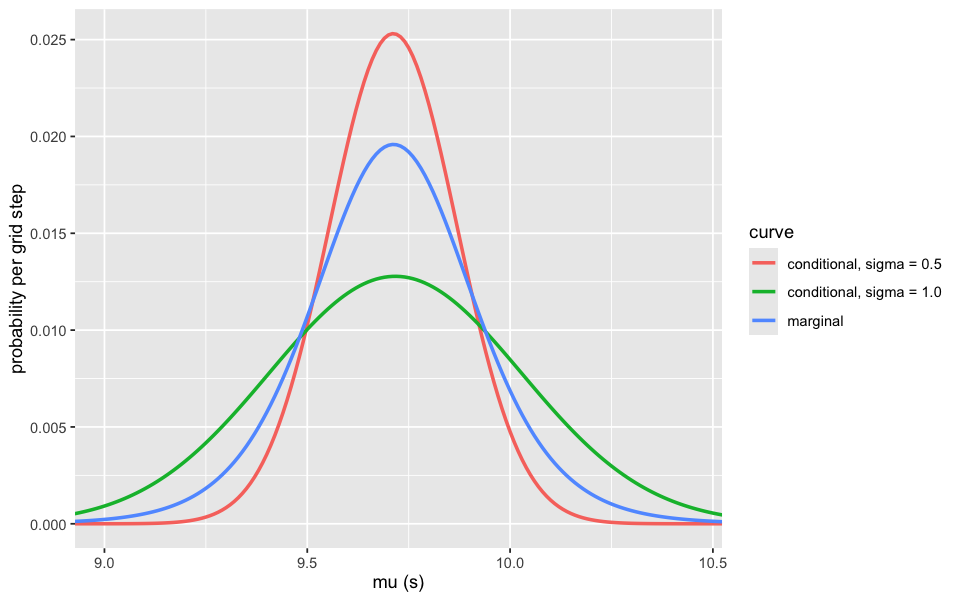

In [7]:
marginal_mu    <- grid |> group_by(mu)    |> summarise(p = sum(weight))
marginal_sigma <- grid |> group_by(sigma) |> summarise(p = sum(weight))

# conditional at the grid value of sigma closest to 0.5 and to 1.0
sigma_values <- unique(grid$sigma)
s05 <- sigma_values[which.min(abs(sigma_values - 0.5))]
s10 <- sigma_values[which.min(abs(sigma_values - 1.0))]
cond_05 <- grid |> filter(sigma == s05) |> mutate(p = weight / sum(weight))
cond_10 <- grid |> filter(sigma == s10) |> mutate(p = weight / sum(weight))

bind_rows(marginal_mu |> mutate(curve = "marginal"),
          cond_05 |> select(mu, p) |> mutate(curve = "conditional, sigma = 0.5"),
          cond_10 |> select(mu, p) |> mutate(curve = "conditional, sigma = 1.0")) |>
  ggplot(aes(x = mu, y = p, colour = curve)) + geom_line(linewidth = 1) +
  coord_cartesian(xlim = c(9, 10.45)) + labs(x = "mu (s)", y = "probability per grid step")

c(mean_mu = sum(marginal_mu$mu * marginal_mu$p), mean_sigma = sum(marginal_sigma$sigma * marginal_sigma$p))

## 4. The same model in Stan

*Slides "The normal model in Stan", "The fit: P04's posterior" and "With draws, marginalising is free".* Each row of the draws is a pair (μ, σ). The μ column alone is the marginal of μ: no adding up is needed.

Running MCMC with 4 sequential chains...



Chain 1 Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:

Chain 1 Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in '/var/folders/_0/d0ly2hg91t7070djmv3fxryr0000gp/T/RtmpygLRke/model-516e7924deb.stan', line 13, column 2 to column 24)

Chain 1 If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,

Chain 1 but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Chain 1 



Chain 1 finished in 0.0 seconds.
Chain 2 finished in 0.0 seconds.


Chain 3 Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:

Chain 3 Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in '/var/folders/_0/d0ly2hg91t7070djmv3fxryr0000gp/T/RtmpygLRke/model-516e7924deb.stan', line 13, column 2 to column 24)

Chain 3 If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,

Chain 3 but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Chain 3 



Chain 3 finished in 0.0 seconds.
Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.0 seconds.
Total execution time: 0.6 seconds.



variable,mean,sd,5%,95%,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
mu,9.7140548,0.2300865,9.3449689,10.086748,1.002045,2031.881
sigma,0.7003905,0.2035207,0.4530769,1.083449,1.001631,2146.702
y_new,9.7351140,0.7733570,8.4764401,10.979328,1.001294,3771.432


$num_divergent
[1] 0 0 0 0

$num_max_treedepth
[1] 0 0 0 0

$ebfmi
[1] 0.9129517 0.9280570 1.1062926 1.0872223

Warning message:
“Dropping 'draws_df' class as required metadata was removed.”


.draw,mu,sigma,y_new
<int>,<dbl>,<dbl>,<dbl>
1,9.868398,0.5244290,9.039181
2,9.947347,0.5643143,10.562762
3,9.739168,0.8284883,9.942264
4,9.799769,0.7711815,9.686435
5,9.970619,0.5974584,9.706097
6,9.484089,0.5889569,9.822288


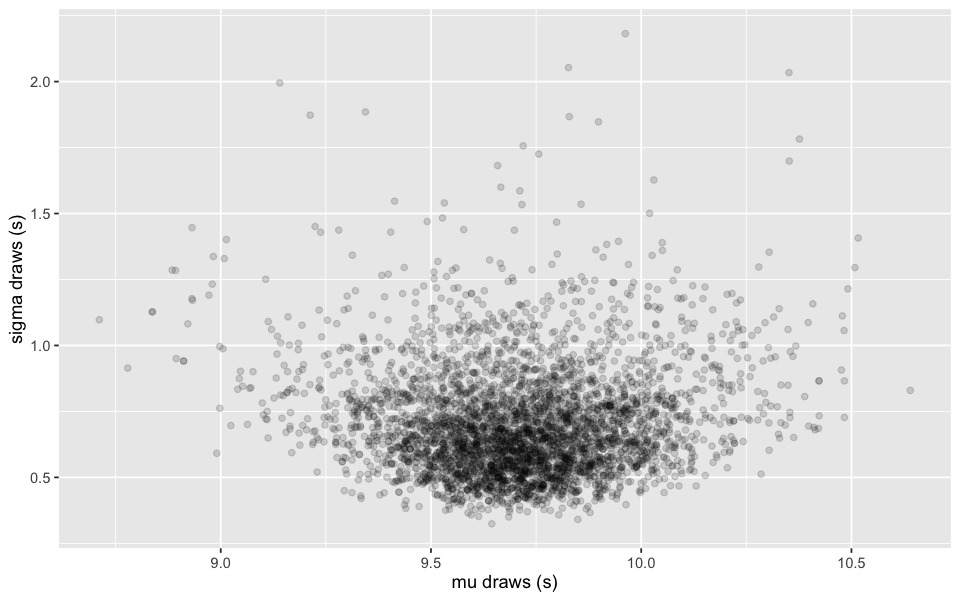

In [8]:
mod <- cmdstan_model("models/normal.stan")
fit <- mod$sample(data = list(N = length(y), y = y), chains = 4, seed = 2026, refresh = 0)
fit$summary(c("mu", "sigma", "y_new"), "mean", "sd", ~quantile(.x, c(0.05, 0.95)), "rhat", "ess_bulk")
fit$diagnostic_summary()

draws <- fit$draws(format = "df")
head(draws |> select(.draw, mu, sigma, y_new))

ggplot(draws, aes(x = mu, y = sigma)) + geom_point(alpha = 0.15) +
  labs(x = "mu draws (s)", y = "sigma draws (s)")

Grid and Stan agree: the histogram of the μ column follows the grid's marginal (rescaled to a density).

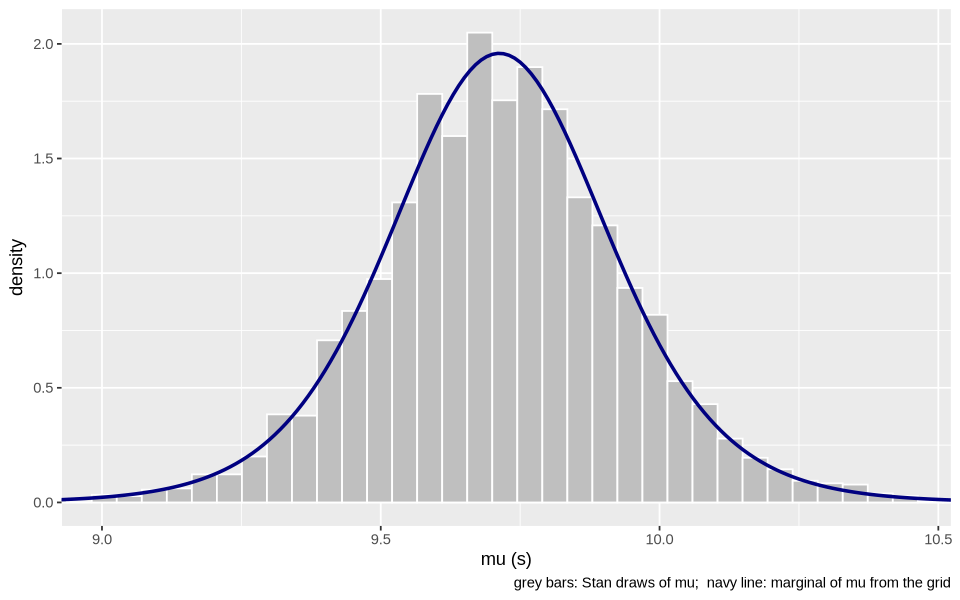

In [6]:
step <- diff(marginal_mu$mu)[1]
ggplot() +
  geom_histogram(data = draws, aes(x = mu, y = after_stat(density)), bins = 50, fill = "grey75", colour = "white") +
  geom_line(data = marginal_mu, aes(x = mu, y = p / step), colour = "navy", linewidth = 1) +
  coord_cartesian(xlim = c(9, 10.45)) +
  labs(x = "mu (s)", y = "density", caption = "grey bars: Stan draws of mu;  navy line: marginal of mu from the grid")

## 5. Her average versus her next attempt

*Slides "Her average versus her next attempt" and "Questions the draws answer".* `y_new` was drawn inside each draw: ỹ⁽ˢ⁾ ~ Normal(μ⁽ˢ⁾, σ⁽ˢ⁾).

quantity,q5,q95
<chr>,<dbl>,<dbl>
her average mu,9.353451,10.08904
next attempt y_new,8.477899,10.89428


P_mu_below_10           P_next_below_10         P_sigma_above_0.8 
                  0.90375                   0.66050                   0.23625 
P_next_within_half_second 
                  0.50325

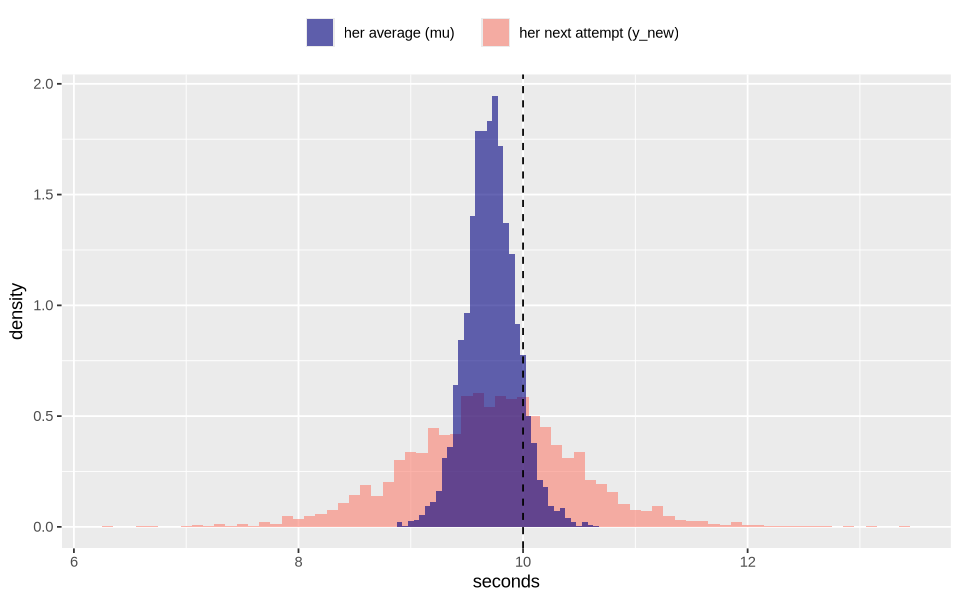

In [7]:
tibble(quantity = c("her average mu", "next attempt y_new"),
       q5  = c(quantile(draws$mu, 0.05), quantile(draws$y_new, 0.05)),
       q95 = c(quantile(draws$mu, 0.95), quantile(draws$y_new, 0.95)))

ggplot(draws) +
  geom_histogram(aes(x = y_new, y = after_stat(density), fill = "her next attempt (y_new)"), binwidth = 0.1, alpha = 0.6) +
  geom_histogram(aes(x = mu,    y = after_stat(density), fill = "her average (mu)"),         binwidth = 0.05, alpha = 0.6) +
  geom_vline(xintercept = 10, linetype = "dashed") +
  scale_fill_manual(values = c("her next attempt (y_new)" = "salmon", "her average (mu)" = "navy"), name = NULL) +
  theme(legend.position = "top") +
  labs(x = "seconds", y = "density")

c(P_mu_below_10   = mean(draws$mu < 10),
  P_next_below_10 = mean(draws$y_new < 10),
  P_sigma_above_0.8 = mean(draws$sigma > 0.8),
  P_next_within_half_second = mean(abs(draws$y_new - 10) < 0.5))

## 6. Try it: more attempts

*Slide "Worked example: answers".* Simulate 100 attempts with the same average and spread as P04's ten, refit, and compare the two intervals. Change `n_attempts` and run again.

In [8]:
n_attempts <- 100
y_more <- rnorm(n_attempts)
y_more <- (y_more - mean(y_more)) / sd(y_more) * sd(y) + mean(y)    # same mean and SD as P04
fit_more <- mod$sample(data = list(N = n_attempts, y = y_more), chains = 4, seed = 2026, refresh = 0)
draws_more <- fit_more$draws(format = "df")

tibble(attempts = c(10, 10, n_attempts, n_attempts),
       quantity = c("mu", "y_new", "mu", "y_new"),
       q5  = c(quantile(draws$mu, 0.05), quantile(draws$y_new, 0.05), quantile(draws_more$mu, 0.05), quantile(draws_more$y_new, 0.05)),
       q95 = c(quantile(draws$mu, 0.95), quantile(draws$y_new, 0.95), quantile(draws_more$mu, 0.95), quantile(draws_more$y_new, 0.95))) |>
  mutate(width = q95 - q5)

Running MCMC with 4 sequential chains...

Chain 1 finished in 0.0 seconds.
Chain 2 finished in 0.0 seconds.
Chain 3 finished in 0.0 seconds.
Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.0 seconds.
Total execution time: 0.5 seconds.



attempts,quantity,q5,q95,width
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
10,mu,9.353451,10.089045,0.7355942
10,y_new,8.477899,10.894278,2.4163791
100,mu,9.606717,9.811659,0.2049422
100,y_new,8.714271,10.743102,2.0288312
